# P1 / 02: the S05 residual signal split by abnormal turnover (15 minutes)

Protocol: [`001_claude_p1_turnover_reversal_preregistration.md`](../../discussions/Short_Term_Momentum/001_claude_p1_turnover_reversal_preregistration.md), arm I.

S05 engine (sector-ETF residual s-score, entries |s| > 1.25, `x10` exits, 1% per stock, ≤ 100 positions, S05b measured costs). New entries are allowed only for stocks in one abnormal-volume tercile, known at the previous close: `T1` (low), `T2`, `T3` (high); `ALL` = no mask.

Gates (α = 0.05): **I1** T1 − T3 mean gross per trade > 0 in the `ALL` run (bootstrap over entry days); **I2** `T1` beats 200 random-membership placebos on net total return and Sharpe; **I3** `T1` net > 0 at 1× and 2× cost, bootstrap lower bound > 0 at blocks 10/20/40.

In [1]:
N_PLACEBO = 200
N_JOBS = -1
PER_YEAR, WINDOW_S = 4, 3.0

import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, p1, s04, s05, s05b
from equity_trading.alpaca import ALPACA_VERSION, download_years, sample_quote_spreads
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("P1_SYNTHETIC") == "1"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})
GCOL = {0: "#2a78d6", 1: "#8a8a84", 2: "#eb6834"}          # T1 low AV, T2, T3 high AV
GNAME = {0: "T1 low AV", 1: "T2", 2: "T3 high AV"}

PCFG = p1.P1Config()
YEARS = list(range(2020, 2026))                      # 2026 not used
YEARS_D = list(range(2019, 2026))                    # 1Day bars; 2019 is volume warm-up only
CFG = s05.S05Config(close_long=1.0, close_short=-1.0, n_placebo=N_PLACEBO)   # x10 exits (S05c)
ARMS = {"ALL": None, "T1": 0, "T2": 1, "T3": 2}
if SYNTHETIC:
    YEARS, N_PLACEBO = [2024, 2025], 8
tag = ("synthetic_" if SYNTHETIC else "") + f"alpaca{ALPACA_VERSION}_s05{s05.S05_VERSION}_p{s04.PANEL_VERSION}_p1{p1.P1_VERSION}"
OUT = ROOT / "notebooks" / "Short_Term_Momentum" / ("02_synthetic" if SYNTHETIC else "02")
OUT.mkdir(parents=True, exist_ok=True)
CACHE = work_dir() / "results" / "p1_02" / tag
CACHE.mkdir(parents=True, exist_ok=True)
QUOTE_CACHE = vendor_dir("Alpaca") / "quote_samples" / f"{CFG.timeframe}_w{WINDOW_S:g}s"
QUOTE_CACHE.mkdir(parents=True, exist_ok=True)
ACOL = {"ALL": "#444444", "T1": GCOL[0], "T2": GCOL[1], "T3": GCOL[2]}
if SYNTHETIC:
    from equity_trading.universe import SECTOR_ETF_01, UNIVERSE_01
    ETF_OF = {s: SECTOR_ETF_01[k] for k, v in UNIVERSE_01.items() for s in v}
else:
    constituents = pd.read_csv(ROOT / "src" / "equity_trading" / "reference" / "sp500_constituents_20260913.csv")
    ETF_OF = dict(zip(constituents["Symbol"], constituents["GICS Sector"].map(s05.SECTOR_ETF)))
STOCKS = sorted(ETF_OF)
ETFS = sorted(set(ETF_OF.values()))
print(f"synthetic={SYNTHETIC} | exits x10 | arms={list(ARMS)} | placebos={N_PLACEBO}")

synthetic=False | exits x10 | arms=['ALL', 'T1', 'T2', 'T3'] | placebos=200


## 1. Data, measured costs, estimation (as S05b/S05c), abnormal-volume terciles

In [2]:
t0 = time.time()
if SYNTHETIC:
    panel, _ = s04.synthetic_ohlc_panel(YEARS)
else:
    download_years(STOCKS + ETFS + ["SPY"], CFG.timeframe, YEARS, workers=8)
    panel = s04.cached_panel(STOCKS + ETFS + ["SPY"], CFG.timeframe, YEARS, ffill_bars=CFG.ffill_bars)
have = set(panel.symbols)
TRADED = [s for s in STOCKS if s in have and ETF_OF[s] in have]
SC = np.array([panel.symbols.index(s) for s in TRADED])
EC = np.array([panel.symbols.index(ETF_OF[s]) for s in TRADED])
QUOTED = sorted(set(TRADED) | {ETF_OF[s] for s in TRADED})
SESSIONS = s05b.sample_sessions(YEARS, PER_YEAR, seed=42)
if SYNTHETIC:
    samples = pd.DataFrame([(s, 3e-4, 10, k, d) for d in SESSIONS for k in range(26) for s in QUOTED],
                           columns=["symbol", "half_spread", "n_quotes", "slot", "date"])
else:
    for d in [d for d in SESSIONS if not (QUOTE_CACHE / f"{d}.parquet").exists()]:
        sample_quote_spreads(QUOTED, d, s05b.slot_starts(YEARS, d), window_s=WINDOW_S, cache_dir=QUOTE_CACHE)
    samples = pd.concat([pd.read_parquet(QUOTE_CACHE / f"{d}.parquet") for d in SESSIONS], ignore_index=True)
H = s05b.cost_array(panel.index, panel.day_start, panel.symbols, s05b.cost_model(samples))
est_path = CACHE / "params.npz"
if est_path.exists():
    P = dict(np.load(est_path))
else:
    P = s05.estimate_all(panel, SC, EC, CFG, s05.first_decision_day(CFG)); np.savez(est_path, **P)

# abnormal volume from daily bars (known at each close), terciles among traded stocks
if SYNTHETIC:
    rng = np.random.default_rng(0)
    days = pd.DatetimeIndex(pd.to_datetime(list(panel.days)))
    AV = pd.DataFrame(rng.lognormal(0, 0.3, (len(days), len(TRADED))), index=days, columns=TRADED)
else:
    download_years(TRADED, "1Day", YEARS_D, workers=8)
    _, _, V = p1.load_daily(TRADED, YEARS_D)
    AV = p1.abnormal_volume(V, PCFG)
LAB = p1.labels_on_days(p1.group_labels(AV, 3), panel.days, TRADED)
sizes = pd.DataFrame({GNAME[g]: (LAB == g).sum(1) for g in range(3)}, index=pd.to_datetime(list(panel.days)))
print(f"panel {panel.c.shape}, traded {len(TRADED)}, costs median {np.median(H[:, SC]) * 1e4:.2f} bps, "
      f"labelled stock-days {(LAB >= 0).mean():.1%}, ready in {time.time() - t0:.0f}s")
display(sizes.describe().round(1))

15Min: 0 batches to download (0 symbol-years), 8 parallel requests
1Day: 0 batches to download (0 symbol-years), 8 parallel requests
panel (39064, 513), traded 501, costs median 3.01 bps, labelled stock-days 97.6%, ready in 67s


,T1 low AV,T2,T3 high AV
count,1508.0,1508.0,1508.0
mean,162.7,162.9,163.2
std,2.5,2.5,2.5
min,157.0,157.0,158.0
25%,160.0,160.0,161.0
50%,163.0,164.0,164.0
75%,164.0,165.0,165.0
max,166.0,166.0,167.0


## 2. Backtests per arm (1×, 2×, 0× measured cost)

12 backtests in 1.3 min; trading starts 2020-02-03


,total_return,sharpe,max_drawdown,mean_daily,days
ALL 1x,0.0987,0.3605,0.0782,0.0001,1486.0
ALL 2x,-0.0991,-0.2965,0.1918,-0.0001,1486.0
ALL 0x,0.3343,0.9937,0.0562,0.0002,1486.0
T1 1x,-0.0379,-0.1066,0.1334,-0.0000,1486.0
T1 2x,-0.2296,-0.9025,0.2669,-0.0002,1486.0
T1 0x,0.1894,0.6412,0.0995,0.0001,1486.0
T2 1x,0.0805,0.3236,0.1020,0.0001,1486.0
T2 2x,-0.1166,-0.4433,0.2334,-0.0001,1486.0
T2 0x,0.3369,1.1208,0.0457,0.0002,1486.0
T3 1x,0.1646,0.4923,0.0885,0.0001,1486.0


,trades,mean_gross_bps,cost_per_trade_bps,median_bars,avg_open_positions,gross_over_cost
ALL,16121.0,20.154,12.963,232.0,99.968,1.465
T1,17733.0,11.476,13.284,191.0,99.923,0.823
T2,17462.0,17.905,12.686,200.0,99.918,1.344
T3,17225.0,23.498,13.453,202.0,99.925,1.688


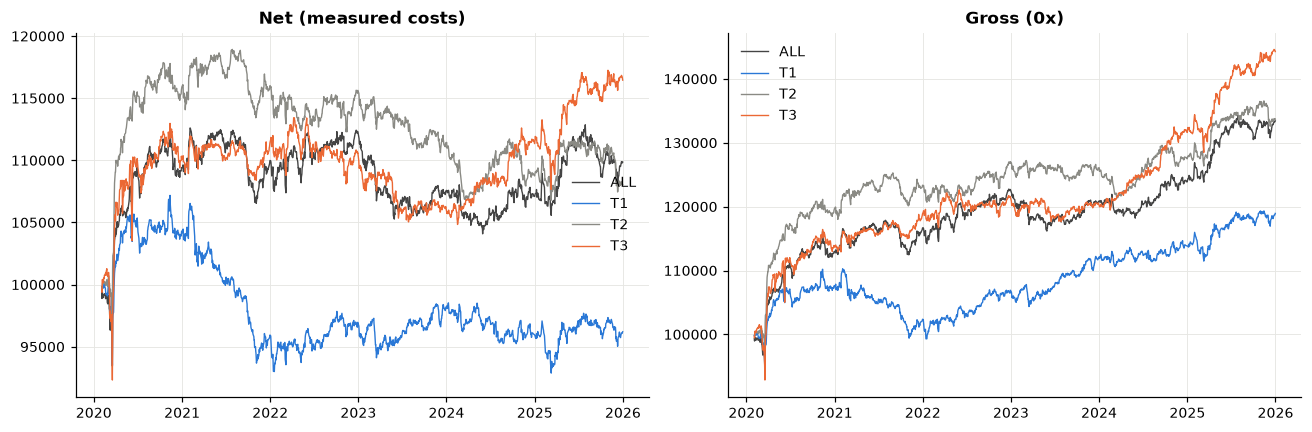

In [3]:
MASK = {a: (None if g is None else LAB == g) for a, g in ARMS.items()}
runs, rows, tstats = {}, {}, {}
t0 = time.time()
for arm in ARMS:
    for cm in (1.0, 2.0, 0.0):
        runs[(arm, cm)] = s05.backtest(panel, P, SC, EC, replace(CFG, cost_mult=cm), record=(cm == 1.0), half_spread=H,
                                       entry_mask=MASK[arm])
START = runs[("ALL", 1.0)]["first_day"]
for (arm, cm), r in runs.items():
    rows[f"{arm} {cm:g}x"] = s04.perf_metrics(r["daily_equity"], CFG.initial_equity, START)
for arm in ARMS:
    r = runs[(arm, 1.0)]; tr = r["trades"]
    tstats[arm] = {"trades": len(tr), "mean_gross_bps": 1e4 * tr.gross_ret.mean() if len(tr) else np.nan,
                   "cost_per_trade_bps": 1e4 * r["total_cost"] / tr.notional.sum() if len(tr) else np.nan,
                   "median_bars": tr.bars.median() if len(tr) else np.nan,
                   "avg_open_positions": float(r["n_open"][panel.index.tz_localize(None) >= START].mean()),
                   "gross_over_cost": tr.gross_pnl.sum() / r["total_cost"] if r["total_cost"] > 0 else np.nan}
    tr.drop(columns=["i"]).to_csv(OUT / f"trades_{arm}.csv", index=False, float_format="%.6g")
    r["daily_equity"].to_csv(OUT / f"daily_equity_{arm}.csv", header=["equity"], float_format="%.2f")
METRICS = pd.DataFrame(rows).T
print(f"{len(runs)} backtests in {(time.time() - t0) / 60:.1f} min; trading starts {START.date()}")
display(METRICS.round(4)); display(pd.DataFrame(tstats).T.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for arm in ARMS:
    for cm, i in ((1.0, 0), (0.0, 1)):
        e = runs[(arm, cm)]["daily_equity"]; e = e[e.index >= START]
        ax[i].plot(e.index, e, color=ACOL[arm], lw=0.9, label=arm)
ax[0].set_title("Net (measured costs)"); ax[1].set_title("Gross (0x)")
for a in ax: a.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. I1: gross per trade by tercile in the `ALL` run

Each trade carries the tercile in force when its signal was taken. T3 < 0 would be the paper's momentum reading at 15 minutes (reported, not judged).

In [4]:
tr_all = runs[("ALL", 1.0)]["trades"].copy()
lrow = p1.trade_label_rows(tr_all["entry_bar"].to_numpy(), panel.day_start)
tr_all["tercile"] = LAB[lrow, tr_all["i"].to_numpy()]
tr_all["entry_day"] = lrow
by = tr_all.groupby("tercile").agg(trades=("gross_ret", "size"), mean_gross_bps=("gross_ret", lambda x: 1e4 * x.mean()),
                                   median_bars=("bars", "median"), mean_abs_s_entry=("s_entry", lambda x: x.abs().mean()))
by.index = by.index.map(lambda g: GNAME.get(g, "unlabelled"))
by.to_csv(OUT / "all_run_by_tercile.csv", float_format="%.5g")
display(by.round(3))
I1 = p1.cluster_bootstrap_diff(tr_all["gross_ret"].to_numpy(), tr_all["tercile"].to_numpy(), tr_all["entry_day"].to_numpy(),
                               0, 2, 10_000, CFG.seed, 0.05)
print(f"T1 - T3 mean gross per trade: {1e4 * I1[0]:.2f} bps, 95% [{1e4 * I1[1]:.2f}, {1e4 * I1[2]:.2f}] (bootstrap over entry days)")

,trades,mean_gross_bps,median_bars,mean_abs_s_entry
tercile,,,,
unlabelled,85,-68.772,256.0,4.009
T1 low AV,6811,17.874,226.0,4.155
T2,5268,22.638,230.0,4.094
T3 high AV,3957,22.681,242.0,4.003


T1 - T3 mean gross per trade: -4.81 bps, 95% [-28.61, 18.30] (bootstrap over entry days)


## 4. I2: `T1` against random-membership placebos

Each placebo allows entries only for a random set of stocks of the same daily size as T1. Same engine, exits and costs.

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   31.4s
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:  2.3min
[Parallel(n_jobs=-1)]: Done 154 tasks      | elapsed:  5.5min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  7.0min finished


200 placebos in 7.0 min


,value,percentile,p_upper,placebo_median,placebo_p95
total_return,-0.0379,0.0,1.0,0.1049,0.1846
sharpe,-0.1066,0.0,1.0,0.3546,0.5898


random direction (T1 trades, reported): {'observed_gross': 17640.5773, 'p_upper': 0.0018, 'percentile': 99.83, 'placebo_p95': 9795.6134}


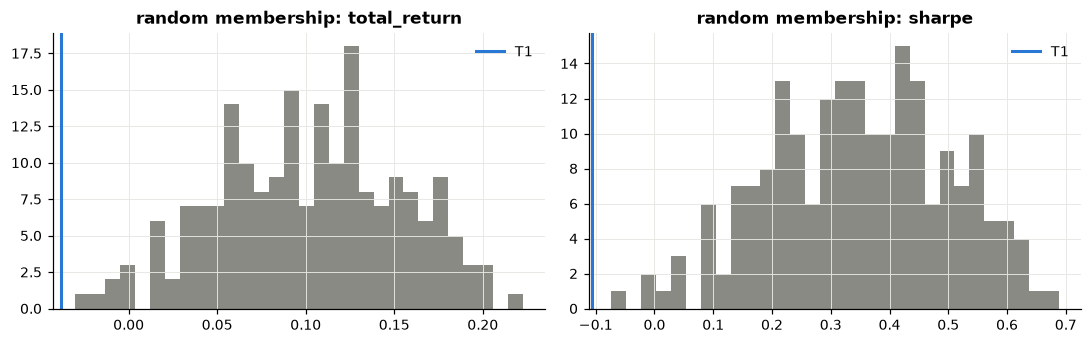

In [5]:
from joblib import Parallel, delayed
pl_path = CACHE / f"placebo_membership_T1_{N_PLACEBO}.parquet"
if pl_path.exists():
    PL = pd.read_parquet(pl_path)
else:
    t0 = time.time()
    seeds = [CFG.seed * 1000 + i for i in range(N_PLACEBO)]
    masks = (p1.random_masks(LAB, 0, np.random.default_rng(s)) for s in seeds)
    PL = pd.DataFrame(Parallel(n_jobs=N_JOBS, batch_size=1, verbose=5)(
        delayed(p1.run_mask_backtest)(panel, P, SC, EC, CFG, m, s, START, H) for s, m in zip(seeds, masks)))
    PL.to_parquet(pl_path); print(f"{N_PLACEBO} placebos in {(time.time() - t0) / 60:.1f} min")
PL.to_csv(OUT / "placebo_membership_T1.csv", index=False, float_format="%.6g")
t1 = METRICS.loc["T1 1x"]
RANKS = {k: s04.placebo_rank(t1[k], PL[k].to_numpy()) for k in ("total_return", "sharpe")}
RAND_DIR = s05.random_direction_test(runs[("T1", 1.0)]["trades"].gross_pnl.to_numpy(), n=10_000, seed=CFG.seed)
display(pd.DataFrame(RANKS).T.round(4)); print("random direction (T1 trades, reported):", {k: round(v, 4) for k, v in RAND_DIR.items()})
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, k in zip(ax, ("total_return", "sharpe")):
    a.hist(PL[k], bins=30, color="#8a8a84"); a.axvline(t1[k], color=GCOL[0], lw=2, label="T1")
    a.set_title(f"random membership: {k}"); a.legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. Gates

In [6]:
e = runs[("T1", 1.0)]["daily_equity"]; e = e[e.index >= START]
BOOT = {b: s04.block_bootstrap_mean(e.pct_change().dropna().to_numpy(), b, 10_000, CFG.seed) for b in (10, 20, 40)}
G = p1.gates_i(I1, RANKS, METRICS.loc["T1 1x"].to_dict(), METRICS.loc["T1 2x"].to_dict(), BOOT)
display(pd.DataFrame(BOOT, index=["mean", "lo95", "hi95"]).T)
summary = {"study": "P1-02", "synthetic": SYNTHETIC, "years": YEARS, "config": CFG.as_dict(), "p1_config": PCFG.as_dict(),
           "arms": list(ARMS), "trading_start": str(START.date()), "n_placebo": N_PLACEBO,
           "metrics": METRICS.to_dict(orient="index"), "trade_stats": tstats, "all_run_by_tercile": by.to_dict(orient="index"),
           "I1_T1_minus_T3_gross": {"mean": I1[0], "lo95": I1[1], "hi95": I1[2]}, "placebo_membership_ranks": RANKS,
           "random_direction_T1": RAND_DIR, "bootstrap_T1": {str(k): v for k, v in BOOT.items()}, "gates": G,
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "s05": s05.S05_VERSION, "panel": s04.PANEL_VERSION,
                        "p1": p1.P1_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir()), "cache": str(CACHE)}, indent=2))
print(json.dumps(G, indent=2))

,mean,lo95,hi95
10,-0.00002,-0.000180,0.000139
20,-0.00002,-0.000168,0.000128
40,-0.00002,-0.000139,0.000119


{
  "I1_turnover_dependence": false,
  "I2_vs_random_membership": false,
  "I3_economic": false,
  "verdict": "NO_EDGE",
  "prospective_verdict": "PENDING_2026_HOLDOUT"
}
